# Same epistemic uncertainty, opposite useful acquisitions
## An exact counterexample to acquisition sufficiency of predictive uncertainty

**Question:** Can predictive epistemic uncertainty alone tell us which additional information will reduce uncertainty about a fixed target?

**Construction:** two source models induce exactly the same two-member distribution over target predictions. Their scalar mutual information, probability support and lower/upper epistemic values all agree. Nevertheless, one benefits from source identities and the other from source-stratified target labels. We prove this algebraically, enumerate exact expectations, and verify the response with repeated acquisition draws.

This is a minimal analytic experiment, deliberately not another four-image-dataset benchmark. It removes optimization, model fitting, OOD rankings and representation-learning failures from the argument. Prior image notebooks remain unchanged.

**Claim boundary:** a function of the predictive representation alone cannot universally determine acquisition value. A Bayesian procedure given the full acquisition likelihood can distinguish the situations and update correctly; we implement those updates. This is not a claim that mutual information is numerically wrong, that all epistemic methods fail, or that intervals alone solve the problem.

### Sources and theoretical dependencies

- Hüllermeier & Waegeman (2021), [Aleatoric and epistemic uncertainty](https://doi.org/10.1007/s10994-021-05946-3): distinction between outcome randomness, uncertainty about predictive probabilities, and set-valued representations.
- [Probly](https://github.com/pwhofman/probly): independently check predictive mutual information on the actual categorical second-order representation. Record the installed version. No neural dropout sampling is needed because the two predictive members are exact.
- Hoeffding (1963), [Probability inequalities](https://www.cs.rpi.edu/academics/courses/spring06/random/hoefding.pdf): fixed-sample confidence-set illustration, clearly separated from posterior/epistemic intervals.
- Ni et al., [DAPPr](https://arxiv.org/abs/2605.00600): motivation for comparing predictive uncertainty representations. We do not assert that DAPPr training produces matched scores on these worlds, and do not fabricate neural logits to claim an empirical DAPPr failure.

**Derived directly below:** Bayes' rule, Bernoulli entropy, posterior variance as squared-error Bayes risk, the law of total variance, and the two-world acquisition-sufficiency counterexample. The counterexample is our construction for this study; no novelty claim against the literature is made.

The acquisition laws, priors and hypothesis set are specified, not learned from the four image datasets. Results are conditional on these choices. All sources, equations, code, draws, outputs and plots are saved under a fresh workbook directory.

In [1]:
# Goal: declare the complete experiment and create a new artifact directory.
from pathlib import Path
import sys,json,hashlib,shutil,importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display,Markdown
ROOT=Path.cwd()
if not (ROOT/'real/acquisition_counterexample.py').exists():
    ROOT=ROOT/'Uncertainty_Modeling/EU_AU_Disentanglement/REACH_AISTATS'
sys.path.insert(0,str(ROOT))
from real.acquisition_counterexample import *
SEED=20261029; REPEATS=10000
BUDGETS=[0,1,2,5,10,20,50,100,200]
PRIOR_Q=.5; Q_RANGE=(.25,.75); ALPHA=.05
RUN_DIR=ROOT/'workbook'/('acquisition_counterexample_'+pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ'))
RUN_DIR.mkdir(parents=True,exist_ok=False)
plt.rcdefaults()
print('Artifacts:',RUN_DIR)


Artifacts: /home/mtleao/projects/Concept_Disentaglement/Uncertainty_Modeling/EU_AU_Disentanglement/REACH_AISTATS/workbook/acquisition_counterexample_20261029T192454214626Z


### 1. Same target, different unknown mechanism

In both worlds there are two sources $S\in\{0,1\}$ and one observable input cell $X=0$. The target is the **deployment probability** $T=P(Y=1\mid X=0)=P(Y=1)$. It is the same estimand in both worlds, not two different uncertainty targets.

A latent hypothesis $H\in\{L,H\}$ selects $p_L=0.2$ or $p_H=0.8$. Initially $P(H=H)=q=0.5$.

| Quantity | World M: mixture unknown | World L: target rates unknown |
|---|---|---|
| Deployment source proportion $P(S=1)$ | $p_H$ or $p_L$ | Known $1/2$ |
| Source-0 target rate $P(Y=1\mid S=0)$ | Known 0 | $p_H$ or $p_L$ |
| Source-1 target rate $P(Y=1\mid S=1)$ | Known 1 | Same $p_H$ or $p_L$ |
| Observable input | Always $X=0$ | Always $X=0$ |
| Deployment target probability | $(1-p)0+p1=p$ | $(1/2)p+(1/2)p=p$ |

Therefore both worlds induce exactly

$$Q_q=(1-q)\delta_{\mathrm{Bern}(0.2)}+q\delta_{\mathrm{Bern}(0.8)}.$$

The worlds have different known structural assumptions. Those assumptions are available to an acquisition-aware rule, but absent from a rule restricted to $Q_q$. We do not claim the full parameter posteriors or full information states are identical.

**Fundamental:** projecting a parameter model to target predictions can erase which unknown parameters generated those predictions.

### 2. Equal predictive uncertainty, including upper/lower epistemic values

Let $h(p)=-p\log p-(1-p)\log(1-p)$. Predictive mutual information is

$$U(q)=h(0.2+0.6q)-(1-q)h(0.2)-qh(0.8).$$

At $q=1/2$, both worlds have mean prediction 0.5, probability support $\{0.2,0.8\}$, total predictive entropy $h(0.5)$, and epistemic MI $h(0.5)-h(0.2)$.

To represent uncertainty about the hypothesis weight, explicitly allow $q\in[0.25,0.75]$. This is a declared prior-sensitivity family, **not** a confidence set estimated from data. Define

$$[\underline U,\overline U]=[\min_q U(q),\max_q U(q)].$$

Concavity makes the minimum an endpoint value; symmetry makes the maximum occur at $q=1/2$. The resulting interval is identical in the two worlds. This directly demonstrates that merely replacing one scalar by upper/lower epistemic values does not supply the missing acquisition likelihood.

Below Probly checks the nominal MI. The interval calculation uses the explicit weighted MI formula, avoiding the installed version's known nonuniform-sample-weight path.

In [2]:
# Goal: verify equality of the complete predictive object and calculate actual epistemic bounds.
from probly.representation.distribution.torch_categorical import TorchProbabilityCategoricalDistribution,TorchCategoricalDistributionSample
from probly.quantification import quantify
members=torch.tensor([[.8,.2],[.2,.8]],dtype=torch.float64)
probly_rep=TorchCategoricalDistributionSample(tensor=TorchProbabilityCategoricalDistribution(members),sample_dim=0)
probly_mi=float(quantify(probly_rep).epistemic)
assert abs(probly_mi-float(predictive_eu(PRIOR_Q)))<1e-12
lo,hi=eu_bounds(*Q_RANGE)
initial=pd.DataFrame([dict(world=w,predictive_mean=.5,target_support_lower=.2,target_support_upper=.8,
    epistemic_mi=probly_mi,epistemic_lower=float(lo),epistemic_upper=float(hi),
    target_variance=float(target_variance(PRIOR_Q))) for w in WORLDS])
initial.to_csv(RUN_DIR/'identical_initial_uncertainty.csv',index=False)
display(initial)


,world,predictive_mean,target_support_lower,target_support_upper,epistemic_mi,epistemic_lower,epistemic_upper,target_variance
0,mixture_unknown,0.5,0.2,0.8,0.192745,0.147044,0.192745,0.09
1,label_unknown,0.5,0.2,0.8,0.192745,0.147044,0.192745,0.09


### 3. Specify what each acquisition actually observes

Each acquisition costs one observation; there are no hidden noisy source identities or unknown label-noise rates.

| Acquisition | World M | World L |
|---|---|---|
| Unlabeled input | $X=0$, same under both hypotheses | $X=0$, same under both hypotheses |
| Deployment source identity | $S\sim\mathrm{Bern}(p)$ | $S\sim\mathrm{Bern}(1/2)$, independent of H |
| Source-stratified reference label | Query source 0; $Y=0$, independent of H | Query source 0; $Y\sim\mathrm{Bern}(p)$ |

The reference source is fixed by the sampling design and known reliably. A reference label is not an unstratified deployment label: the latter would be Bernoulli(p) in both worlds and would help both. Distinguishing these channels is essential.

Bayes' rule updates the hypothesis weight after each acquisition. For an informative channel, $k$ successes in $n$ draws give

$$\operatorname{logit}(q_{n,k})=\operatorname{logit}(q)+k\log(0.8/0.2)+(n-k)\log(0.2/0.8).$$

For uninformative channels the likelihoods agree, so the posterior remains q. This is a correct update, not an artificially frozen baseline. The same evidence updates both endpoints of the prior-weight range using this monotone map.

### 4. Exact proposition: same predictive representation cannot determine action value

Use expected reduction in posterior variance of the **same target probability** T as acquisition value. Under squared error, the optimal estimate is the posterior mean and its Bayes risk is posterior variance. This is not the variance of the binary outcome Y.

Initially $\operatorname{Var}(T)=0.6^2q(1-q)$, which is 0.09 at q=1/2. For one informative Bernoulli observation, posterior weights become 0.8 or 0.2, with equal marginal probability. The remaining variance is $0.6^2(0.8)(0.2)=0.0576$. Hence expected risk reduction is **0.0324**. An uninformative observation leaves variance 0.09, so its reduction is **0**.

Thus source identity is strictly preferable in M; reference target label is strictly preferable in L. Both cost the same, and the predictive representation is exactly the same.

**Proof of insufficiency:** any deterministic policy that receives only Q must choose the same action in both worlds. It therefore cannot choose the uniquely best action in both. A randomized Q-only policy choosing identities with probability r incurs one-step regret $0.0324(1-r)$ in M and $0.0324r$ in L (ignoring inputs, which only worsen regret). Its worst-world regret is at least **0.0162**, attained at r=1/2. This proves a limitation of predictive-representation-only policies, not of policies given the full likelihoods.

**Stronger than scalar matching:** any scalar or interval that is solely a function of Q also agrees across worlds. This includes the nominal MI and prior-sensitive MI interval above. An arbitrary scalar could encode structural information, so we do not claim every possible scalar is insufficient.

**Transition:** enumerate exact acquisition outcomes to verify the proof and its behavior at larger budgets.

In [3]:
# Goal: calculate action values exactly, without Monte Carlo or neural training.
exact=pd.DataFrame([dict(world=w,action=a,n=n,**exact_expected(w,a,n,PRIOR_Q,Q_RANGE))
                    for w in WORLDS for a in ACTIONS for n in BUDGETS])
one=exact[exact.n==1].copy()
assert np.isclose(one[(one.world=='mixture_unknown')&(one.action=='source_id')].variance_reduction.iloc[0],.0324)
assert np.isclose(one[(one.world=='label_unknown')&(one.action=='reference_label')].variance_reduction.iloc[0],.0324)
exact.to_csv(RUN_DIR/'exact_acquisition_values.csv',index=False)
one.to_csv(RUN_DIR/'one_observation_counterexample.csv',index=False)
display(one[['world','action','expected_variance','variance_reduction','expected_eu']])
regret=pd.DataFrame([dict(probability_choose_identity=r,regret_M=.0324*(1-r),regret_L=.0324*r,
    worst_world_regret=max(.0324*(1-r),.0324*r)) for r in np.linspace(0,1,101)])
regret.to_csv(RUN_DIR/'score_only_policy_regret.csv',index=False)


,world,action,expected_variance,variance_reduction,expected_eu
1,mixture_unknown,inputs,0.0900,0.0000,0.192745
10,mixture_unknown,source_id,0.0576,0.0324,0.126467
19,mixture_unknown,reference_label,0.0900,0.0000,0.192745
28,label_unknown,inputs,0.0900,0.0000,0.192745
37,label_unknown,source_id,0.0900,0.0000,0.192745
46,label_unknown,reference_label,0.0576,0.0324,0.126467


### 5. Repeated acquisitions: verify exact expectations and inspect interval behavior

Draw the true hypothesis once per replicate from the specified q=1/2 prior, then draw nested acquisition streams. All channels within that replicate share its hypothesis. The two informative channels use paired observations across worlds, so differences cannot be attributed to Monte Carlo noise.

For each budget, save posterior q, target mean, target variance, predictive MI, and lower/upper MI after updating the weight family. The expected endpoint curves average over the nominal q=1/2 observation law; they are **not robust expectations over all priors**. Individual MI realizations need not decrease at every step, even though expected posterior variance cannot increase under this correctly specified Bayesian experiment.

We also include a separate fixed-n confidence-set illustration for the true target T. Under an informative channel, retain p=0.2 or p=0.8 if its distance from the empirical success rate is at most sqrt(log(2/alpha)/(2n)). Hoeffding gives at least 1-alpha inclusion at each fixed budget. Under uninformative channels retain both. Empty sets are flagged as rejection with NaN endpoints; never count them as zero uncertainty. Means of these widths are reported **conditional on non-rejection**, alongside rejection and inclusion rates. No simultaneous-over-time guarantee is claimed.

Important distinction: Bayesian support still contains both hypotheses after any finite full-support Bernoulli sample (ignoring floating-point underflow). Its support width does not shrink. Posterior concentration, epistemic MI intervals and confidence-set widths are different objects.

In [4]:
# Goal: simulate properly updated channels, retaining all raw sufficient statistics and failures.
rng=np.random.default_rng(SEED)
truth=np.where(rng.random(REPEATS)<PRIOR_Q,P_HIGH,P_LOW)
max_n=max(BUDGETS)
info_draws=(rng.random((REPEATS,max_n))<truth[:,None]).astype(np.uint8)
uninfo_ids=(rng.random((REPEATS,max_n))<.5).astype(np.uint8)
np.savez_compressed(RUN_DIR/'acquisition_draws.npz',true_target=truth,informative=info_draws,uninformative_ids=uninfo_ids)
rows=[]
for world in WORLDS:
    for action in ACTIONS:
        yes=informative(world,action)
        draw=info_draws if yes else uninfo_ids if action=='source_id' else np.zeros_like(info_draws)
        cumulative=np.column_stack([np.zeros(REPEATS,dtype=int),draw.cumsum(1)])
        for n in BUDGETS:
            k=cumulative[:,n];post=posterior_q(PRIOR_Q,n,k,yes)
            qlo=posterior_q(Q_RANGE[0],n,k,yes);qhi=posterior_q(Q_RANGE[1],n,k,yes)
            ulo,uhi=eu_bounds(qlo,qhi)
            tlo,thi,empty=confidence_set(n,k,yes,ALPHA)
            rows.append(pd.DataFrame(dict(world=world,action=action,n=n,replicate=np.arange(REPEATS),truth=truth,successes=k,
                posterior_q=post,posterior_target_mean=P_LOW+(P_HIGH-P_LOW)*post,target_variance=target_variance(post),
                epistemic= predictive_eu(post),epistemic_lower=ulo,epistemic_upper=uhi,
                confidence_lower=tlo,confidence_upper=thi,confidence_width=thi-tlo,rejected=empty,
                confidence_included=(tlo<=truth)&(truth<=thi))))
sim=pd.concat(rows,ignore_index=True)
sim.to_csv(RUN_DIR/'replicate_results.csv.gz',index=False,compression='gzip')
summary=sim.groupby(['world','action','n'],as_index=False).agg(
    mean_variance=('target_variance','mean'),variance_sd=('target_variance','std'),
    mean_eu=('epistemic','mean'),mean_eu_lower=('epistemic_lower','mean'),mean_eu_upper=('epistemic_upper','mean'),
    conditional_mean_confidence_width=('confidence_width','mean'),rejection_rate=('rejected','mean'),inclusion=('confidence_included','mean'))
summary=summary.merge(exact,on=['world','action','n'],validate='one_to_one')
summary['mc_standard_error']=summary.variance_sd/np.sqrt(REPEATS)
summary['absolute_error']=abs(summary.mean_variance-summary.expected_variance)
assert (summary.absolute_error<=6*summary.mc_standard_error+1e-10).all()
summary.to_csv(RUN_DIR/'acquisition_summary.csv',index=False)
display(summary[summary.n.isin([0,1,20,200])].round(6))


,world,action,n,mean_variance,variance_sd,mean_eu,mean_eu_lower,mean_eu_upper,conditional_mean_confidence_width,rejection_rate,inclusion,expected_variance,variance_reduction,expected_eu,expected_eu_lower,expected_eu_upper,mc_standard_error,absolute_error
0,label_unknown,inputs,0,0.09000,0.000000,0.192745,0.147044,0.192745,0.60000,0.0000,1.0000,0.090000,0.000000,0.192745,0.147044,0.192745,0.000000,0.000000
1,label_unknown,inputs,1,0.09000,0.000000,0.192745,0.147044,0.192745,0.60000,0.0000,1.0000,0.090000,0.000000,0.192745,0.147044,0.192745,0.000000,0.000000
5,label_unknown,inputs,20,0.09000,0.000000,0.192745,0.147044,0.192745,0.60000,0.0000,1.0000,0.090000,0.000000,0.192745,0.147044,0.192745,0.000000,0.000000
8,label_unknown,inputs,200,0.09000,0.000000,0.192745,0.147044,0.192745,0.60000,0.0000,1.0000,0.090000,0.000000,0.192745,0.147044,0.192745,0.000000,0.000000
9,label_unknown,reference_label,0,0.09000,0.000000,0.192745,0.147044,0.192745,0.60000,0.0000,1.0000,0.090000,0.000000,0.192745,0.147044,0.192745,0.000000,0.000000
10,label_unknown,reference_label,1,0.05760,0.000000,0.126467,0.057668,0.189067,0.60000,0.0000,1.0000,0.057600,0.032400,0.126467,0.057668,0.189067,0.000000,0.000000
14,label_unknown,reference_label,20,0.00038,0.004477,0.000840,0.000465,0.001472,0.00126,0.0000,0.9995,0.000376,0.089624,0.000830,0.000457,0.001472,0.000045,0.000004
17,label_unknown,reference_label,200,0.00000,0.000000,0.000000,0.000000,0.000000,0.00000,0.0004,0.9996,0.000000,0.090000,0.000000,0.000000,0.000000,0.000000,0.000000
18,label_unknown,source_id,0,0.09000,0.000000,0.192745,0.147044,0.192745,0.60000,0.0000,1.0000,0.090000,0.000000,0.192745,0.147044,0.192745,0.000000,0.000000
19,label_unknown,source_id,1,0.09000,0.000000,0.192745,0.147044,0.192745,0.60000,0.0000,1.0000,0.090000,0.000000,0.192745,0.147044,0.192745,0.000000,0.000000


### 6. Read the result as an acquisition counterexample

First figure: exact expected target variance and simulated means. The correct acquisition swaps between worlds while all initial predictive uncertainty agrees. Inputs never help because their law is identical under both hypotheses.

Second figure: updated lower/upper **epistemic MI**. The shaded region is the average of the specified prior-sensitive endpoints, not a confidence band or a range across replicates. The bounds alone were initially equal; only applying the distinct channel likelihoods reveals the different responses.

Third figure: confidence-set width, conditional on non-rejection. This is a different target-probability interval, included to connect to the earlier identification framework. See the saved inclusion/rejection rates before interpreting contraction.

findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Failed to find font weight 300 for DejaVu Sans, now using 400.


findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans.


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Failed to find font weight 300 for DejaVu Sans, now using 400.


findfont: Failed to find font weight 300 for STIXGeneral, now using 400.


... (1,181 outputs left out)

findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


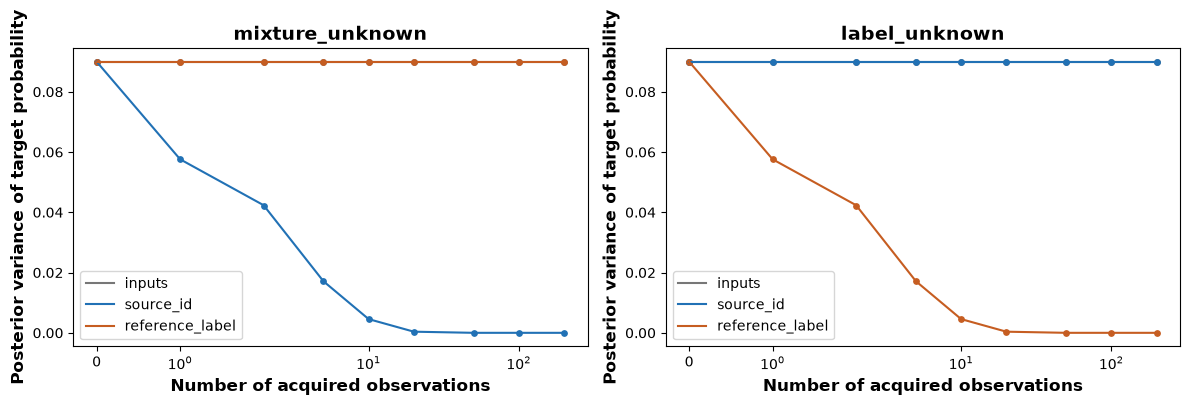

findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


... (1,575 outputs left out)

findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


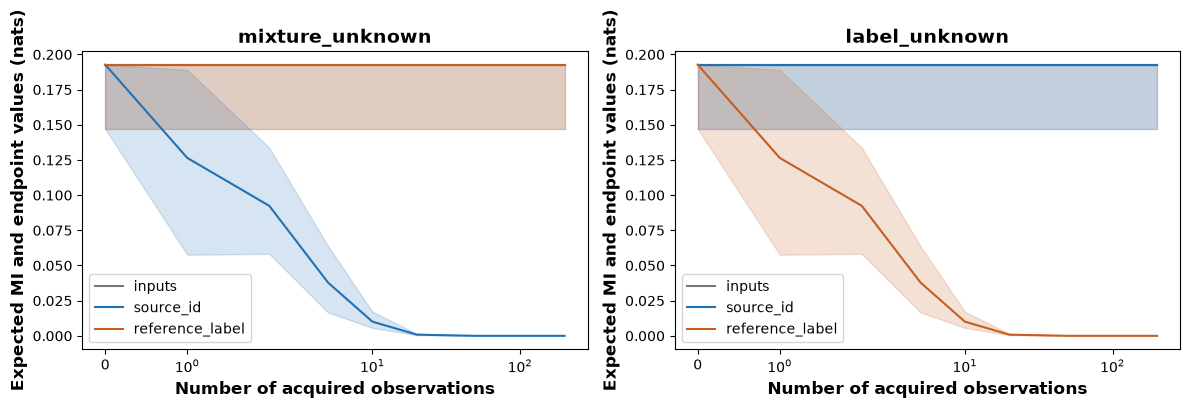

findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


... (1,365 outputs left out)

findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


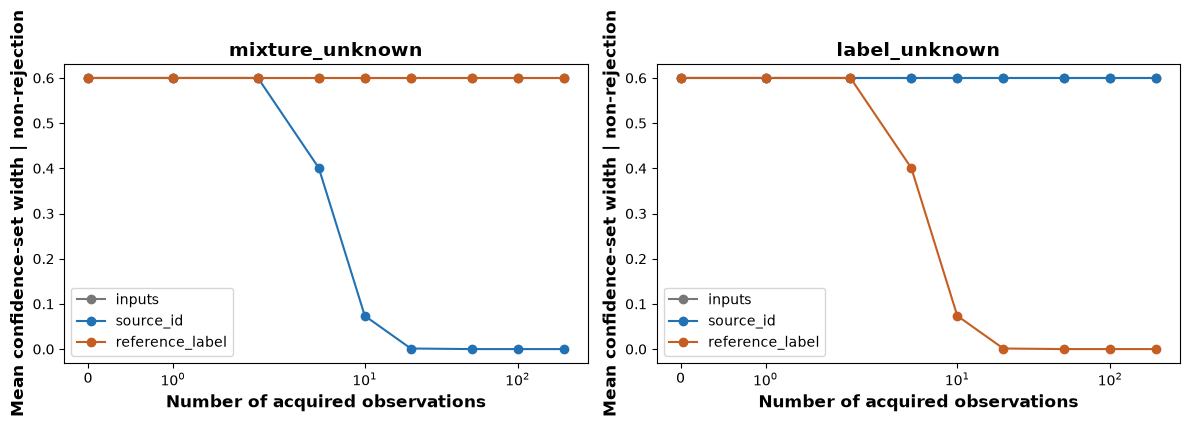

findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


... (790 outputs left out)

findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


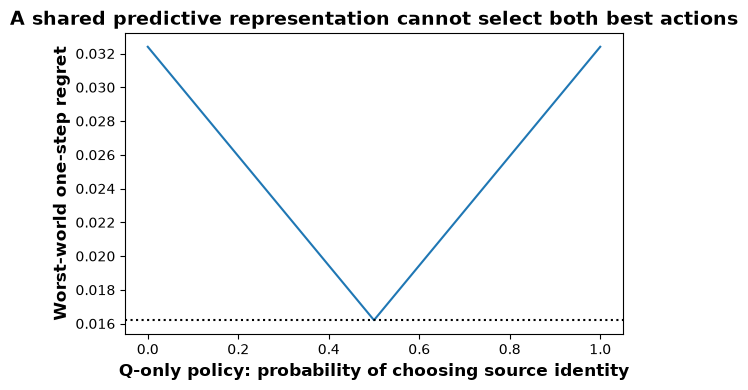

In [5]:
# Goal: produce labeled figures that separate risk, epistemic intervals, and probability confidence sets.
colors=dict(inputs='#777777',source_id='#2171b5',reference_label='#c65d21')
for kind in ['risk','epistemic_bounds','confidence_width']:
    fig,axes=plt.subplots(1,2,figsize=(12,4),squeeze=False)
    for ax,world in zip(axes[0],WORLDS):
        for action in ACTIONS:
            f=summary[(summary.world==world)&(summary.action==action)]
            if kind=='risk':
                ax.plot(f.n,f.expected_variance,color=colors[action],label=action)
                ax.scatter(f.n,f.mean_variance,color=colors[action],s=15)
                ylabel='Posterior variance of target probability'
            elif kind=='epistemic_bounds':
                ax.fill_between(f.n,f.expected_eu_lower,f.expected_eu_upper,color=colors[action],alpha=.18)
                ax.plot(f.n,f.expected_eu,color=colors[action],label=action)
                ylabel='Expected MI and endpoint values (nats)'
            else:
                ax.plot(f.n,f.conditional_mean_confidence_width,'o-',color=colors[action],label=action)
                ylabel='Mean confidence-set width | non-rejection'
        ax.set(title=world,xscale='symlog',xlabel='Number of acquired observations',ylabel=ylabel)
        ax.legend()
    fig.tight_layout()
    for ext in ['png','pdf']:fig.savefig(RUN_DIR/f'{kind}.{ext}',dpi=170,bbox_inches='tight')
    plt.show()
fig,ax=plt.subplots(figsize=(6,4))
ax.plot(regret.probability_choose_identity,regret.worst_world_regret)
ax.axhline(.0162,color='black',ls=':')
ax.set(xlabel='Q-only policy: probability of choosing source identity',ylabel='Worst-world one-step regret',title='A shared predictive representation cannot select both best actions')
fig.tight_layout()
for ext in ['png','pdf']:fig.savefig(RUN_DIR/f'policy_regret.{ext}',dpi=170,bbox_inches='tight')
plt.show()


### 7. Scientific conclusion and limits

**Established:** the predictive distribution over distributions can be identical while the best acquisition differs. Therefore its scalar epistemic summaries and upper/lower epistemic summaries are not universally sufficient for acquisition choice. The missing object is the relation between unknown parameters and each candidate observation channel.

**Not established:** that MI is an incorrect measure of predictive disagreement; that DAPPr training is defective; that all scalar functions or full-parameter Bayesian methods fail; that our prior-sensitive intervals are confidence bounds; or that a new detector beats another on images.

**Implication for our project:** the useful output is an acquisition-indexed uncertainty response, not merely a richer static uncertainty number. The earlier source-mixture identification analysis supplies precisely the type of observation-channel structure missing from a prediction-only summary. Intervals remain useful for expressing admissible uncertainty, but must be connected to what an acquisition observes.

The construction is stylized: the input is deliberately uninformative, hypotheses and priors are specified, the source-0 reference channel is available, identities are perfect, and acquisition costs are equal. These choices isolate the logical failure of universal sufficiency; they do not estimate how often the failure occurs in natural datasets.

In [6]:
# Goal: export the exact conclusion, proof, sources, implementations and reproducibility metadata.
mi=float(predictive_eu(PRIOR_Q));ulo,uhi=eu_bounds(*Q_RANGE)
text=f'''# Counterexample: identical predictive uncertainty, reversed useful acquisition

Both worlds have the same target T=P(Y=1), the same predictive law over Bernoulli(0.2)/Bernoulli(0.8), and equal hypothesis weights.

- Initial epistemic MI: {mi:.9f} nats.
- Same epistemic interval for prior weights [0.25,0.75]: [{float(ulo):.9f}, {float(uhi):.9f}] nats.
- Initial target-probability posterior variance: 0.09.
- One informative acquisition reduces expected variance to 0.0576: value 0.0324.
- World M: source identities have value 0.0324; source-0 labels have value 0.
- World L: source-0 labels have value 0.0324; source identities have value 0.
- Inputs have value 0 in both worlds.
- Any policy restricted to the shared predictive representation has worst-world one-step regret at least 0.0162 (allowing randomized choices).

This proves predictive-representation-only acquisition insufficiency in the declared model. It does not prove that epistemic measures are incorrect, that static intervals repair the problem, or that DAPPr training fails. Correct Bayesian updates using the full channel likelihood succeed.

The notebook includes the algebraic proof, exact outcome enumeration, 10,000 paired repetitions, fixed-n confidence-set illustration, and clearly separated probability and epistemic intervals.
'''
(RUN_DIR/'RESULTS.md').write_text(text);display(Markdown(text))
config=dict(seed=SEED,repeats=REPEATS,budgets=BUDGETS,p_low=P_LOW,p_high=P_HIGH,prior_q=PRIOR_Q,
    prior_weight_range=Q_RANGE,confidence_alpha=ALPHA,cost_per_observation=1,
    target='deployment probability P(Y=1)',reference_label_channel='target label from known source 0',
    versions={p:importlib.metadata.version(p) for p in ['numpy','scipy','pandas','torch','probly']})
(RUN_DIR/'config.json').write_text(json.dumps(config,indent=2))
notebook=json.loads((ROOT/'acquisition_counterexample.ipynb').read_text())
(RUN_DIR/'SOURCES.md').write_text(''.join(notebook['cells'][1]['source']))
proof='\n\n'.join(''.join(c['source']) for c in notebook['cells'] if c['cell_type']=='markdown')
(RUN_DIR/'PROOF_AND_PROTOCOL.md').write_text(proof)
for c in notebook['cells']:
    if c['cell_type']=='code':c['outputs']=[];c['execution_count']=None
(RUN_DIR/'source_notebook.ipynb').write_text(json.dumps(notebook,indent=1))
for source in [ROOT/'real/acquisition_counterexample.py',ROOT/'tests/test_acquisition_counterexample.py',ROOT/'scripts/build_acquisition_counterexample.py']:
    shutil.copy2(source,RUN_DIR/source.name)
(RUN_DIR/'README.md').write_text('Start with executed.ipynb, RESULTS.md and PROOF_AND_PROTOCOL.md. SOURCES.md lists theoretical dependencies. Exact tables are independent of simulation; replicate_results.csv.gz and acquisition_draws.npz retain all simulated observations. The runner saves the executed notebook and hashed artifact manifest.')
print('Complete:',RUN_DIR)


# Counterexample: identical predictive uncertainty, reversed useful acquisition

Both worlds have the same target T=P(Y=1), the same predictive law over Bernoulli(0.2)/Bernoulli(0.8), and equal hypothesis weights.

- Initial epistemic MI: 0.192744757 nats.
- Same epistemic interval for prior weights [0.25,0.75]: [0.147044215, 0.192744757] nats.
- Initial target-probability posterior variance: 0.09.
- One informative acquisition reduces expected variance to 0.0576: value 0.0324.
- World M: source identities have value 0.0324; source-0 labels have value 0.
- World L: source-0 labels have value 0.0324; source identities have value 0.
- Inputs have value 0 in both worlds.
- Any policy restricted to the shared predictive representation has worst-world one-step regret at least 0.0162 (allowing randomized choices).

This proves predictive-representation-only acquisition insufficiency in the declared model. It does not prove that epistemic measures are incorrect, that static intervals repair the problem, or that DAPPr training fails. Correct Bayesian updates using the full channel likelihood succeed.

The notebook includes the algebraic proof, exact outcome enumeration, 10,000 paired repetitions, fixed-n confidence-set illustration, and clearly separated probability and epistemic intervals.


Complete: /home/mtleao/projects/Concept_Disentaglement/Uncertainty_Modeling/EU_AU_Disentanglement/REACH_AISTATS/workbook/acquisition_counterexample_20261029T192454214626Z
